# Self-financing cash and delivery identities

Family 34. Marks are per held asset unit, and option marks already include contract multipliers. Pending delivery is an owned claim. Settlement moves it into settled cash and holdings once without creating wealth.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Public workflow

The executable example uses only supplied or generated inputs.

In [2]:
"""Family 34: funded accounts, collateral and physical option delivery."""
from convexity.math import wealth

account = wealth.Account([2., 0.], 10000.)
marks = [1000., 110.]
print('Before exercise:', account.wealth(marks))
account = wealth.exercise_delivery(account, 0, 2, underlying_index=1,
                                   shares_per_contract=100, cash_per_contract=-10000)
print('Pending exercise:', account.wealth(marks), account.pending_holdings, account.pending_cash)
account = wealth.settle(account)
print('Settled:', account.wealth(marks), account.holdings, account.cash)
account = wealth.accrue(account, borrowing_factor=1.01, distributions=[0., 1.])
print('After borrowing and dividend:', account.wealth(marks))
print('Futures variation cash:', wealth.futures_variation(wealth.Account([0.], 100), [2], [100], [101], multipliers=50).cash)
print('Attribution:', wealth.pnl_attribution(lambda x: x[0]**3, [2.], [2.1], [12.], [[12.]]))


Before exercise: 12000.0
Pending exercise: 12000.0 [  0. 200.] -20000.0
Settled: 12000.0 [  0. 200.] -10000.0
After borrowing and dividend: 12100.0
Futures variation cash: 200.0
Attribution: Attribution(exact=1.261000000000001, first_order=1.200000000000001, second_order=0.06000000000000011, residual=0.0009999999999998344)


## Conservation through delivery and the Taylor remainder

Exercise at intrinsic value and subsequent settlement conserve marked wealth. Away from the expansion point, delta and gamma leave an explicit repricing remainder.

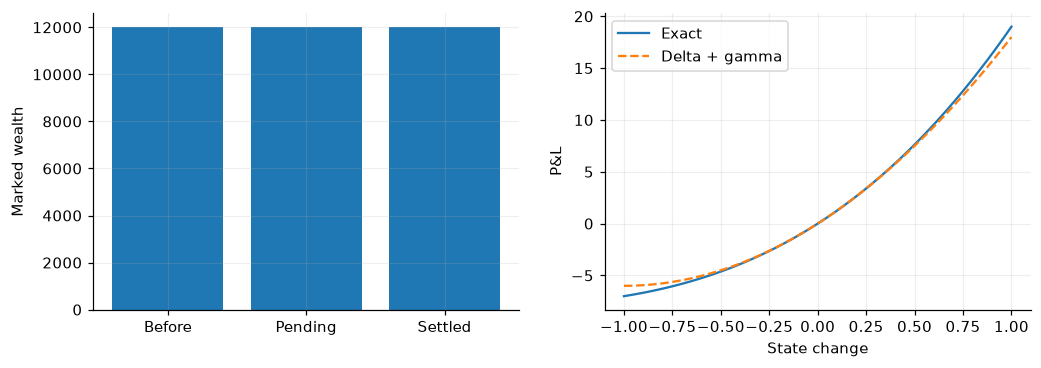

In [3]:
a = wealth.Account([2., 0.], 10000.)
b = wealth.exercise_delivery(a, 0, 2, underlying_index=1, shares_per_contract=100, cash_per_contract=-10000)
c = wealth.settle(b)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(['Before', 'Pending', 'Settled'], [z.wealth([1000., 110.]) for z in (a, b, c)])
axes[0].set(ylabel='Marked wealth')
shocks = np.linspace(-1., 1., 100)
results = [wealth.pnl_attribution(lambda x: x[0]**3, [2.], [2.+shock], [12.], [[12.]]) for shock in shocks]
axes[1].plot(shocks, [z.exact for z in results], label='Exact')
axes[1].plot(shocks, [z.first_order+z.second_order for z in results], label='Delta + gamma', linestyle='--')
axes[1].set(xlabel='State change', ylabel='P&L'); axes[1].legend(); plt.show()

## Scope of this evidence

These experiments illustrate the declared finite catalog, not live trading performance. See the [contracts and limitations](../docs/decision_mathematics.md) and `tests/math/decisions/` for mathematical acceptance checks.